In [42]:
import numpy as np
import matplotlib.pyplot as plt

## Computing posterior using beta-binomial model

Problem: toss a coin $N$ times and infer the probability of heads

Variables: $y_n=1$ denotes the event that the $n$'th trail was heads, $y_n=0$ represents the event that the $n$'th trial was tails, data is $\mathcal{D}=\{y_n:n=1:N\}$.

Assume: $y_n\approx\mathrm{Ber}(\theta)$ where $\theta\in[0,1]$ is the probability of heads

Compute: $p(\theta|\mathcal{D})$; **assume conjugate prior**

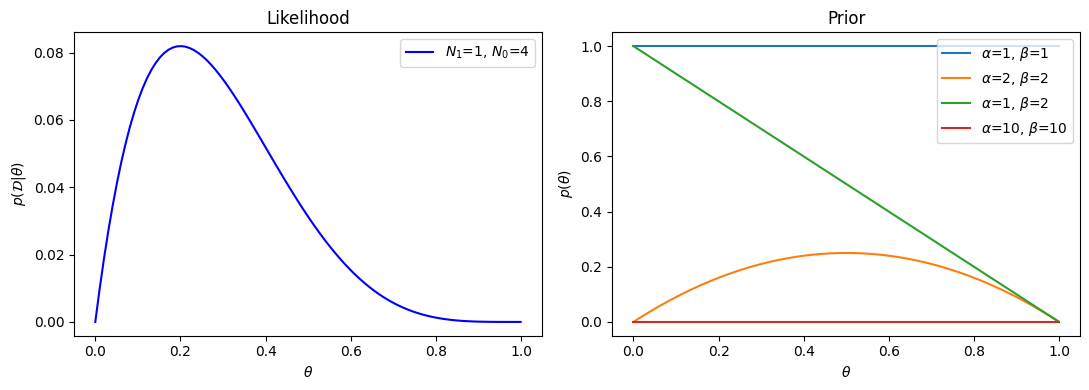

In [43]:
# Compute likelihood 
def bernoulli_likelihood(theta, N_0, N_1):
    """
    Computes bernoulli likelihood PDF for N=2 numbers, p(D|theta)

    N_0 = number of tails
    N_1 = number of heads

    theta in [0, 1] = probability of heads
    """
    return theta**N_1 * (1-theta)**N_0


# Compute prior
def bernoulli_prior(theta, alpha, beta):
    """
    Computes bernoulli conjugate prior, p(theta)
        **this is the pdf of a beta distribution**

    alpha -
    beta -
    """
    return theta**(alpha-1) * (1-theta)**(beta-1)

# define data set
N_0 = 4     # number of tails
N_1 = 1     # number of heads
alpha = [1, 2, 1, 10]
beta = [1, 2, 2, 10]
theta = np.linspace(0.0, 0.999, 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(theta, bernoulli_likelihood(theta, N_0, N_1), "b-", lw=1.5,
         label=f"$N_1$={N_1}, $N_0$={N_0}")
ax1.set_xlabel(r"$\theta$")
ax1.set_ylabel(r"$p(\mathcal{D}|\theta)$")
ax1.set_title("Likelihood")
ax1.legend(loc="upper right")

for a, b in zip(alpha, beta):
    ax2.plot(theta, bernoulli_prior(theta, a, b), lw=1.5,
             label=rf"$\alpha$={a}, $\beta$={b}")
ax2.set_xlabel(r"$\theta$")
ax2.set_ylabel(r"$p(\theta)$")
ax2.set_title("Prior")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()
plt.close()

The strength of the prior is controlled by $N'=\alpha+\beta$; this is called the equivalent sample size, since it plays a role analogous to the observed sample size $N=N_0+N_1$. If we set $\alpha=\beta=2$, it's like saying we have seen 2 heads and 2 tails already, placing a very weak preference for $\theta=0.5$.

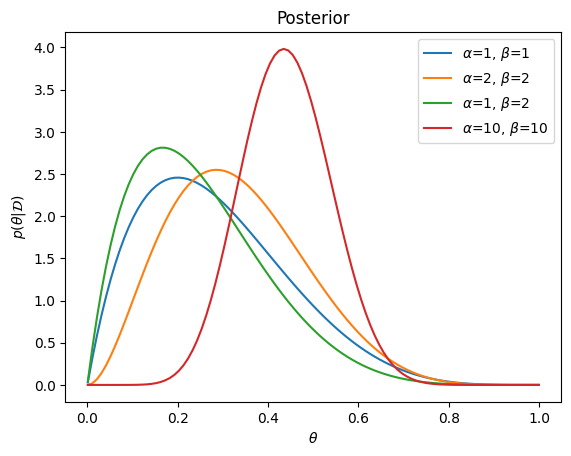

In [44]:
from scipy.special import beta as beta_fn

theta = np.linspace(0.001, 0.999, 100)   # start just above 0 to avoid the alpha=0.5 blow-up

# Calculate and plot normalised posterior
fig, ax = plt.subplots(1, 1)

for a, b in zip(alpha, beta):
    bernoulli_posterior = (bernoulli_likelihood(theta, N_0, N_1)
                           * bernoulli_prior(theta, a, b)
                           / beta_fn(a + N_1, b + N_0))
    ax.plot(theta, bernoulli_posterior, lw=1.5,
            label=rf"$\alpha$={a}, $\beta$={b}")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$p(\theta|\mathcal{D})$")
ax.set_title("Posterior")
ax.legend(loc="upper right")
plt.show()

Setting $\alpha$, $\beta$ to higher values corresponds to a higher number of trials, and this is an example of possible overfitting. We are placing a lot of value on the prior. Reducing it to lower numbers shifts the distribution towards our likelihood estimation, which we can see is probably quite off for the case of a coin flip. We simply do not have many trials to train off of in $\mathcal{D}$. 

### Posterior mode (MAP estimate)
The most probable value of the parameter $\theta$ is given by the MAP estimate, $$\hat{\theta}_{\mathrm{map}}=\mathrm{argmax}_{\theta}\mathrm{log}p(\theta)+\mathrm{log}p(\mathcal{D}|\theta),$$
which in the Bernoulli-beta case is given by $$\hat{\theta}_{\mathrm{map}}=\frac{\bar{\alpha}+N_1-1}{\bar{\alpha}+N_1-1+\beta+N_0-1}.$$ 
This can result in some pretty extreme values, and isn't great if we have low counts of $N_1$.



## Bayesian approach - posterior predictive


In [ ]:
# mapping - most common is Hamiltonian MCMC which is availables in packages such as BoTorch